In [1]:
import os
import sys
from pyspark.sql import SparkSession

print("Python:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Spark_Test")
    .getOrCreate()
)

print("Spark version:", spark.version)

Python: c:\Projects\IND320\.venv\Scripts\python.exe
JAVA_HOME: C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot\
Spark version: 3.5.1


In [1]:
import os

os.environ["SPARK_HOME"] = (
    r"C:\Projects\IND320\.venv\Lib\site-packages\pyspark"
)

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Cassandra_Test")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark version:", spark.version)

PySparkRuntimeError: [JAVA_GATEWAY_EXITED] Java gateway process exited before sending its port number.

In [1]:
from pyspark.sql import SparkSession

# Connector-versjonen må matche Spark- og Scala-versjonen din.
# Sjekk med: spark.version / pyspark.__version__
spark = (
    SparkSession.builder
    .appName("cassandra-test")
    .config("spark.jars.packages",
            "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")  # tilpass til din Spark-versjon
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

# 1) Lag keyspace og tabell via Python-driveren (Spark kan ikke gjøre CREATE KEYSPACE)
from cassandra.cluster import Cluster
session = Cluster(["127.0.0.1"], port=9042).connect()
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS test_ks
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")
session.execute("""
    CREATE TABLE IF NOT EXISTS test_ks.test_tbl (id int PRIMARY KEY, navn text)
""")

# 2) Skriv med Spark
df = spark.createDataFrame([(1, "a"), (2, "b")], ["id", "navn"])
(df.write.format("org.apache.spark.sql.cassandra")
   .options(table="test_tbl", keyspace="test_ks")
   .mode("append").save())

# 3) Les med Spark
(spark.read.format("org.apache.spark.sql.cassandra")
   .options(table="test_tbl", keyspace="test_ks")
   .load().show())

PySparkRuntimeError: [JAVA_GATEWAY_EXITED] Java gateway process exited before sending its port number.

In [2]:
from pymongo import MongoClient
from dotenv import load_dotenv
import os

# Load MongoDB connection string from .env
load_dotenv("C:/Projects/IND320_Project/.env")

uri = os.getenv("MONGODB_URI")

if not uri:
    raise ValueError("MONGODB_URI not found in .env")

# Connect to MongoDB Atlas
client = MongoClient(uri, serverSelectionTimeoutMS=10000)

# Test connection
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

ConfigurationError: The DNS query name does not exist: _mongodb._tcp.your_cluster.mongodb.net.

In [3]:
from dotenv import load_dotenv
from urllib.parse import urlsplit
import os

load_dotenv("C:/Projects/IND320_Project/.env", override=True)

uri = os.getenv("MONGODB_URI")

if uri:
    print("MongoDB host:", urlsplit(uri).hostname)
else:
    print("MONGODB_URI was not found")

MongoDB host: cluster0.pkzkcqj.mongodb.net


In [4]:
from pymongo import MongoClient
from dotenv import load_dotenv
import os

# Last inn oppdatert .env
load_dotenv("C:/Projects/IND320_Project/.env", override=True)

# Hent connection string
uri = os.getenv("MONGODB_URI")

# Test MongoDB
client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

Successfully connected to MongoDB Atlas!


In [5]:
# Select database and collection
db = client["ind320"]
collection = db["connection_test"]

# INSERT
collection.insert_one({
    "_id": "assignment2_test",
    "source": "IND320",
    "status": "testing"
})

# READ
print(collection.find_one({"_id": "assignment2_test"}))

# UPDATE
collection.update_one(
    {"_id": "assignment2_test"},
    {"$set": {"status": "working"}}
)

print(collection.find_one({"_id": "assignment2_test"}))

# DELETE
collection.delete_one({"_id": "assignment2_test"})

print("MongoDB CRUD test completed!")

{'_id': 'assignment2_test', 'source': 'IND320', 'status': 'testing'}
{'_id': 'assignment2_test', 'source': 'IND320', 'status': 'working'}
MongoDB CRUD test completed!


In [10]:
import requests

# API endpoint for NVE reservoir statistics
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Request data from the API
response = requests.get(url, timeout=30)

# Check whether the request succeeded
print("Status code:", response.status_code)

if response.ok:
    data = response.json()
    print("Data type:", type(data))
    print("Preview:", str(data)[:500])
else:
    print("Error:", response.text[:300])

Status code: 200
Data type: <class 'list'>
Preview: [{'dato_Id': '1995-09-03', 'omrType': 'EL', 'omrnr': 4, 'iso_aar': 1995, 'iso_uke': 35, 'fyllingsgrad': 0.94472134, 'kapasitet_TWh': 21.079208, 'fylling_TWh': 19.913979, 'neste_Publiseringsdato': '0001-01-01T00:00:00', 'fyllingsgrad_forrige_uke': 0.9368882, 'endring_fyllingsgrad': 0.007833123}, {'dato_Id': '2020-11-15', 'omrType': 'EL', 'omrnr': 1, 'iso_aar': 2020, 'iso_uke': 46, 'fyllingsgrad': 0.97436064, 'kapasitet_TWh': 6.0032635, 'fylling_TWh': 5.849344, 'neste_Publiseringsdato': '2020-11-2


In [11]:
import pandas as pd

# Convert API response to a DataFrame
df_nve = pd.DataFrame(data)

# Check the structure
print("Shape:", df_nve.shape)
print("Columns:", df_nve.columns.tolist())

# Show the first five rows
display(df_nve.head())

Shape: (14922, 11)
Columns: ['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [12]:
print(df_nve.columns.tolist())
print(df_nve.dtypes)
display(df_nve.head(3))

['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']
dato_Id                         str
omrType                         str
omrnr                         int64
iso_aar                       int64
iso_uke                       int64
fyllingsgrad                float64
kapasitet_TWh               float64
fylling_TWh                 float64
neste_Publiseringsdato          str
fyllingsgrad_forrige_uke    float64
endring_fyllingsgrad        float64
dtype: object


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694


In [13]:
# Create a copy of the API data
df_nve = df_nve.copy()

# Rename columns to match Assignment 1
df_nve = df_nve.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# Convert date to datetime
df_nve["date"] = pd.to_datetime(df_nve["date"])

# Sort data chronologically
df_nve = df_nve.sort_values("date").reset_index(drop=True)

# Display result
display(df_nve.head())

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


In [15]:
# Create a copy of the API data
df_nve = df_nve.copy()

# Rename columns to match Assignment 1
df_nve = df_nve.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# Convert date to datetime
df_nve["date"] = pd.to_datetime(df_nve["date"])

# Sort data chronologically
df_nve = df_nve.sort_values("date").reset_index(drop=True)

# Display result
display(df_nve.head())

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


In [16]:
# Show available area types
print("Area types:")
print(df_nve["area_type"].unique())

# Show area numbers for each type
print("\nArea numbers:")
print(
    df_nve.groupby("area_type")["area_number"]
    .unique()
)

Area types:
<StringArray>
['EL', 'VASS', 'NO']
Length: 3, dtype: str

Area numbers:
area_type
EL      [5, 4, 2, 1, 3]
NO                  [0]
VASS          [2, 3, 1]
Name: area_number, dtype: object


#### NVE API — Reservoir Filling Levels

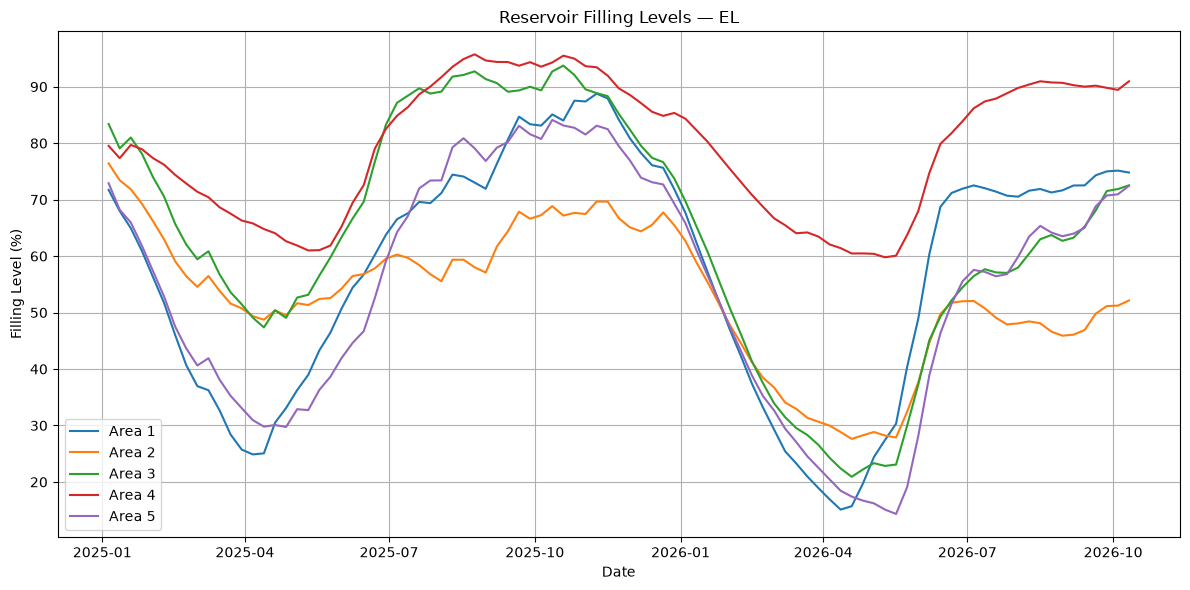

In [18]:
import matplotlib.pyplot as plt

# Select an area type
selected_area = "EL"

# Filter data for the selected area
df_filtered = df_nve[
    df_nve["area_type"] == selected_area
].copy()

# Only show data from 2025 onwards
df_filtered = df_filtered[
    df_filtered["date"] >= "2025-01-01"
]

# Create the plot
plt.figure(figsize=(12, 6))

# Draw one line for each area number
for area_number, group in df_filtered.groupby("area_number"):
    plt.plot(
        group["date"],
        group["fill_level"] * 100,
        label=f"Area {area_number}"
    )

plt.title(f"Reservoir Filling Levels — {selected_area}")
plt.xlabel("Date")
plt.ylabel("Filling Level (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from dotenv import load_dotenv
from pymongo import MongoClient
import os

load_dotenv("C:/Projects/IND320_Project/.env", override=True)

uri = os.getenv("MONGODB_URI")

client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")

print("MongoDB connected successfully!")

In [1]:
from dotenv import load_dotenv
from pymongo import MongoClient
import os

load_dotenv("C:/Projects/IND320_Project/.env", override=True)

uri = os.getenv("MONGODB_URI")

client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

Successfully connected to MongoDB Atlas!


In [2]:
import requests

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=30)

print("Status code:", response.status_code)
print(response.text[:300])



Status code: 200
[{"dato_Id":"1995-09-03","omrType":"EL","omrnr":4,"iso_aar":1995,"iso_uke":35,"fyllingsgrad":0.94472134,"kapasitet_TWh":21.079208,"fylling_TWh":19.913979,"neste_Publiseringsdato":"0001-01-01T00:00:00","fyllingsgrad_forrige_uke":0.9368882,"endring_fyllingsgrad":0.007833123},{"dato_Id":"2020-11-15","o


In [3]:
import pandas as pd

# Convert API response to a DataFrame
data = response.json()
df_nve = pd.DataFrame(data)

# Display the first 5 rows
display(df_nve.head())


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [5]:
# Rename columns to English
df_nve = df_nve.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# Convert date column to datetime
df_nve["date"] = pd.to_datetime(df_nve["date"])

# Sort data chronologically
df_nve = df_nve.sort_values("date").reset_index(drop=True)

# Display first 5 rows
display(df_nve.head())

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


In [6]:
print("Area types:", df_nve["area_type"].unique())
print("Date range:", df_nve["date"].min(), "to", df_nve["date"].max())
print("Total rows:", len(df_nve))

Area types: <ArrowStringArray>
['EL', 'VASS', 'NO']
Length: 3, dtype: str
Date range: 1995-01-08 00:00:00 to 2026-10-11 00:00:00
Total rows: 14922


In [7]:
print("Area types:", df_nve["area_type"].unique())
print("Date range:", df_nve["date"].min(), "to", df_nve["date"].max())
print("Total rows:", len(df_nve))

Area types: <ArrowStringArray>
['EL', 'VASS', 'NO']
Length: 3, dtype: str
Date range: 1995-01-08 00:00:00 to 2026-10-11 00:00:00
Total rows: 14922


In [8]:
# Show available area numbers for each area type
for area_type in ["EL", "NO", "VASS"]:
    area_numbers = sorted(
        df_nve.loc[
            df_nve["area_type"] == area_type,
            "area_number"
        ].unique()
    )

    print(f"{area_type}: {area_numbers}")

EL: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
NO: [np.int64(0)]
VASS: [np.int64(1), np.int64(2), np.int64(3)]


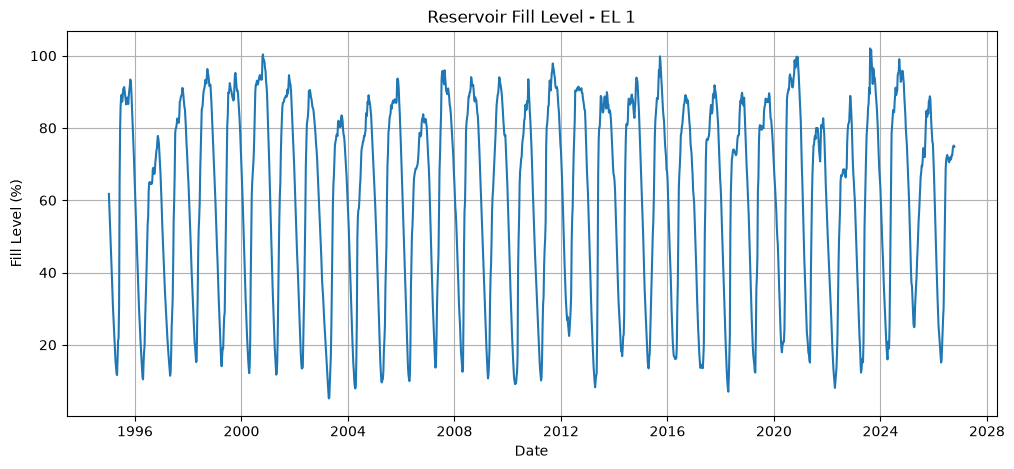

In [9]:
import matplotlib.pyplot as plt

# Select area type and number
area_type = "EL"
area_number = 1

# Filter data for the selected area
df_filtered = df_nve[
    (df_nve["area_type"] == area_type) &
    (df_nve["area_number"] == area_number)
].copy()

# Plot reservoir fill level over time
plt.figure(figsize=(12, 5))

plt.plot(
    df_filtered["date"],
    df_filtered["fill_level"] * 100
)

plt.title(f"Reservoir Fill Level - {area_type} {area_number}")
plt.xlabel("Date")
plt.ylabel("Fill Level (%)")
plt.grid(True)
plt.show()